A step-by-step guide to building four common “heads” in PyTorch—Classification, Detection, Segmentation, and Keypoint—all hooked onto the same backbone. For clarity we’ll use a pretrained ResNet-18 as our backbone (feature extractor), strip off its final layers, and then add each head in turn. At every step I’ll explain what we’re doing, why it matters, and how the code implements it.

## Common Backbone Setup

We’ll load ResNet-18, remove its final global-pool + FC, and expose the last feature map (C×H×W, here 512×7×7 for a 224×224 input).

In [10]:
import torch
import torch.nn as nn
import torchvision.models as models

class Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet18(pretrained=True)
        # Keep everything except avgpool & fc
        self.features = nn.Sequential(*list(resnet.children())[:-2])
        self.out_channels = 512  # ResNet-18’s final conv outputs 512 channels

    def forward(self, x):
        # x: [N,3,224,224] → feats: [N,512,7,7]
        feats = self.features(x)
        return feats

backbone = Backbone()
dummy = torch.randn(2,3,224,224)
feat = backbone(dummy)
print("\n\n ### features shape")
print(feat.shape)  # -> torch.Size([2,512,7,7])




### features shape
torch.Size([2, 512, 7, 7])


- What & Why: We need rich mid/high-level feature maps for all heads. ResNet-18 is a good off-the-shelf extractor.

- How: children()[:-2] chops off the pooling+FC so we keep conv layers only.



## Classification Head
A classification head takes the final feature map, pools it to a vector, and runs it through one (or more) fully-connected layers.



In [11]:
class ClassificationHead(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        # Global average pool → vector
        self.pool = nn.AdaptiveAvgPool2d(1)
        # FC to num_classes
        self.fc = nn.Linear(in_channels, num_classes)

    def forward(self, feats):
        # feats: [N,C,H,W]
        x = self.pool(feats)          # [N,C,1,1]
        x = x.flatten(1)              # [N,C]
        logits = self.fc(x)           # [N,num_classes]
        return logits


In [12]:
clf_head = ClassificationHead(backbone.out_channels, num_classes=10)
logits = clf_head(feat)
print(logits.shape)  # -> [2,10]

torch.Size([2, 10])


Usage:

```
clf_head = ClassificationHead(backbone.out_channels, num_classes=10)
logits = clf_head(feat)
print(logits.shape)  # -> [2,10]
```
- What: Outputs class scores for the whole image.

- Why: Simple global classification tasks (e.g. “Is there a cat?”).

- How: AdaptiveAvgPool2d(1) makes any H×W → 1×1, then a single Linear.

## Detection Head (SSD-style)  
An SSD head predicts, at each spatial location and for each “anchor,” both class scores and box offsets. We’ll implement a simplified version with a single feature map and one anchor per cell.

### SSD Architecture: A Quick Overview
SSD (Single Shot MultiBox Detector) is an object detection architecture introduced by [Liu et al., 2016](https://arxiv.org/abs/1512.02325).
- Uses a **single forward pass** to predict all bounding boxes and class scores
- Attaches **multiple heads** to different backbone layers to detect objects at multiple scales
- At each spatial location in the feature map, it predicts:
  - Class scores for each **anchor box** (predefined size/aspect ratio)
  - Bounding box offsets (regression)

In our simplified version:
- We use **a single feature map** (e.g., from the last backbone layer)
- We assume **1 anchor per cell**
- The detection head outputs:
  - `[N, H×W, num_classes]` classification logits
  - `[N, H×W, 4]` bounding box deltas (center x/y, width, height)

This makes it easier to learn and test before adding complexity like multi-scale detection, NMS, or anchor tuning.


In [15]:
class DetectionHead(nn.Module):
    def __init__(self, in_channels, num_classes, num_anchors=1):
        super().__init__()
        self.num_classes = num_classes     # <== Save here
        self.num_anchors = num_anchors     # <== Save here

        self.cls_conv = nn.Conv2d(in_channels,
                                  num_anchors * num_classes,
                                  kernel_size=3, padding=1)
        self.box_conv = nn.Conv2d(in_channels,
                                  num_anchors * 4,
                                  kernel_size=3, padding=1)

    def forward(self, feats):
        # feats: [N, C, H, W]
        cls_logits = self.cls_conv(feats)
        box_reg = self.box_conv(feats)

        N, _, H, W = cls_logits.shape
        cls_logits = cls_logits.permute(0, 2, 3, 1).contiguous()
        cls_logits = cls_logits.view(N, -1, self.num_classes)  # <== Use self.num_classes

        box_reg = box_reg.permute(0, 2, 3, 1).contiguous()
        box_reg = box_reg.view(N, -1, 4)

        return cls_logits, box_reg


In [16]:
det_head = DetectionHead(backbone.out_channels, num_classes=5)
cls_out, box_out = det_head(feat)
print(cls_out.shape, box_out.shape)

torch.Size([2, 49, 5]) torch.Size([2, 49, 4])


Usage:

```
det_head = DetectionHead(backbone.out_channels, num_classes=5)
cls_out, box_out = det_head(feat)
print(cls_out.shape, box_out.shape)
# -> ([2, 7*7*1, 5], [2, 7*7*1, 4])
```
- What: Produces per-cell class scores & bounding-box adjustments.

- Why: SSD-style single-shot detection is fast; one forward pass gives all boxes.

- How: Two Conv2d heads, then reshape/permute into [N,anchors*H*W, …].

## Segmentation Head  
A segmentation head upsamples the backbone’s low-res feature map back to the input resolution (e.g. 224×224), predicting a per-pixel class.

In [17]:
class SegmentationHead(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        # reduce channels then upsample twice
        self.conv1 = nn.Conv2d(in_channels, 256, kernel_size=3, padding=1)
        self.up1   = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.up2   = nn.ConvTranspose2d(64, num_classes, kernel_size=2, stride=2)

    def forward(self, feats):
        x = nn.ReLU()(self.conv1(feats))   # [N,256,7,7]
        x = nn.ReLU()(self.up1(x))         # [N,128,14,14]
        x = nn.ReLU()(self.conv2(x))       # [N,64,14,14]
        x = self.up2(x)                    # [N,num_classes,28,28]
        # (For 224×224 input you'd repeat upsamples until 224×224)
        return x


In [18]:
seg_head = SegmentationHead(backbone.out_channels, num_classes=21)
seg_out = seg_head(feat)
print(seg_out.shape)  # -> [2,21,28,28]

torch.Size([2, 21, 28, 28])


Usage:

```
seg_head = SegmentationHead(backbone.out_channels, num_classes=21)
seg_out = seg_head(feat)
print(seg_out.shape)  # -> [2,21,28,28]
```

- What: Per-pixel mask logits for each class.
- Why: Scene parsing, semantic segmentation.
- How: ConvTranspose2d upsamples feature maps; intermediate convs refine.

## Keypoint Head  
Often similar to segmentation but producing a heatmap per keypoint (e.g. human body joints). Each pixel’s value is the confidence that a joint lies there.

In [19]:
class KeypointHead(nn.Module):
    def __init__(self, in_channels, num_keypoints):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 256, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(256, num_keypoints, kernel_size=1)

    def forward(self, feats):
        x = nn.ReLU()(self.conv1(feats))  # [N,256,7,7]
        heatmaps = self.conv2(x)          # [N,K,7,7]
        # Usually upsample to input resolution with interp:
        heatmaps = nn.functional.interpolate(heatmaps,
                                             scale_factor=32,
                                             mode='bilinear',
                                             align_corners=False)
        return heatmaps

In [20]:
kp_head = KeypointHead(backbone.out_channels, num_keypoints=17)
kp_out = kp_head(feat)
print(kp_out.shape)

torch.Size([2, 17, 224, 224])


Usage:

```
kp_head = KeypointHead(backbone.out_channels, num_keypoints=17)
kp_out = kp_head(feat)
print(kp_out.shape)  # -> [2,17,224,224]
```

- What: Heatmaps for each keypoint.
- Why: Pose estimation, facial landmarks.
- How: Simple conv stack + upsampling.

### can mix-and-match any head with the backbone:

In [21]:
class FullModel(nn.Module):
    def __init__(self, head_type, **head_kwargs):
        super().__init__()
        self.backbone = Backbone()
        if head_type == 'clf':
            self.head = ClassificationHead(self.backbone.out_channels,
                                           head_kwargs['num_classes'])
        elif head_type == 'det':
            self.head = DetectionHead(self.backbone.out_channels,
                                      head_kwargs['num_classes'],
                                      head_kwargs.get('num_anchors',1))
        elif head_type == 'seg':
            self.head = SegmentationHead(self.backbone.out_channels,
                                         head_kwargs['num_classes'])
        elif head_type == 'kp':
            self.head = KeypointHead(self.backbone.out_channels,
                                     head_kwargs['num_keypoints'])
        else:
            raise ValueError()

    def forward(self, x):
        feats = self.backbone(x)
        return self.head(feats)


In [22]:
model = FullModel('det', num_classes=5, num_anchors=3)
cls_out, box_out = model(torch.randn(1,3,224,224))

In [27]:
print(cls_out.shape, box_out.shape)

torch.Size([1, 147, 5]) torch.Size([1, 147, 4])


## Backbone Types, Advantages, and Visualization in PyTorch

### 1. Backbone Families: Advantages & Limitations

| Backbone            | Params / FLOPs  | Pros                                                                                  | Cons                                                          |
| ------------------- | --------------- | ------------------------------------------------------------------------------------- | ------------------------------------------------------------- |
| **VGG-16**          | ∼138 M / 15.5 B | • Very simple, sequential<br>• Easy to understand and modify                          | • Huge number of parameters<br>• Slow, memory-hungry          |
| **ResNet-50**       | ∼25 M / 4.1 B   | • Residual connections → trains very deep<br>• Excellent accuracy                     | • Still moderately heavy<br>• Residual blocks add overhead    |
| **MobileNet V2**    | ∼3.4 M / 300 M  | • Depthwise separable convs → tiny model<br>• Very fast on CPU/mobile                 | • Lower top-1 accuracy<br>• Narrow feature maps               |
| **EfficientNet-B3** | ∼12 M / 1.8 B   | • Compound scaling (depth, width, res.)<br>• State-of-the-art accuracy/size trade-off | • More complex building blocks<br>• Harder to modify manually |

### When to Choose Which Backbone

* **Mobile/Embedded**: MobileNet, EfficientNet-Lite
* **GPU Training/Research**: ResNet, EfficientNet, Swin Transformer
* **Prototyping**: VGG (for simplicity)

---

## Visualizing Feature Maps in PyTorch

### Step-by-Step PyTorch Code


In [5]:
import torch
import torch.nn as nn
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
import matplotlib.pyplot as plt

# Helper to extract features via hook
# def get_feature_map(model, x, layer_name):
#     feats = {}
#     def hook(module, input, output):
#         feats['map'] = output.detach()
#     layer = dict([*model.named_modules()])[layer_name]
#     layer.register_forward_hook(hook)
#     _ = model(x)
#     return feats['map']

def get_feature_map(model, x, layer_name):
    feats = {}

    def hook(module, input, output):
        feats['map'] = output.detach()

    # Auto-select or debug named_modules()
    named = dict(model.named_modules())
    if layer_name not in named:
        print("Available layers:")
        for k in named.keys():
            print(k)
        raise KeyError(f"Layer '{layer_name}' not found in model")

    layer = named[layer_name]
    layer.register_forward_hook(hook)
    _ = model(x)
    return feats['map']

# Load backbones
backbones = {
    "VGG16": models.vgg16(pretrained=True).features,
    "ResNet50": nn.Sequential(*list(models.resnet50(pretrained=True).children())[:-2]),
    "MobileNetV2": models.mobilenet_v2(pretrained=True).features,
    "EffNetB3": models.efficientnet_b3(pretrained=True).features,
}

# Hook layers
# Adjusted hook_layers dictionary based on actual named layers
hook_layers = {
    "VGG16": "29",                          # VGG is Sequential
    "ResNet50": "7.2.relu",                 # Last ReLU in layer4 block for ResNet50
    "MobileNetV2": "18",                   # Last block in MobileNetV2
    "EffNetB3": "6.5.block.3.1",            # Last conv block in EfficientNetB3
}


### CAT image input

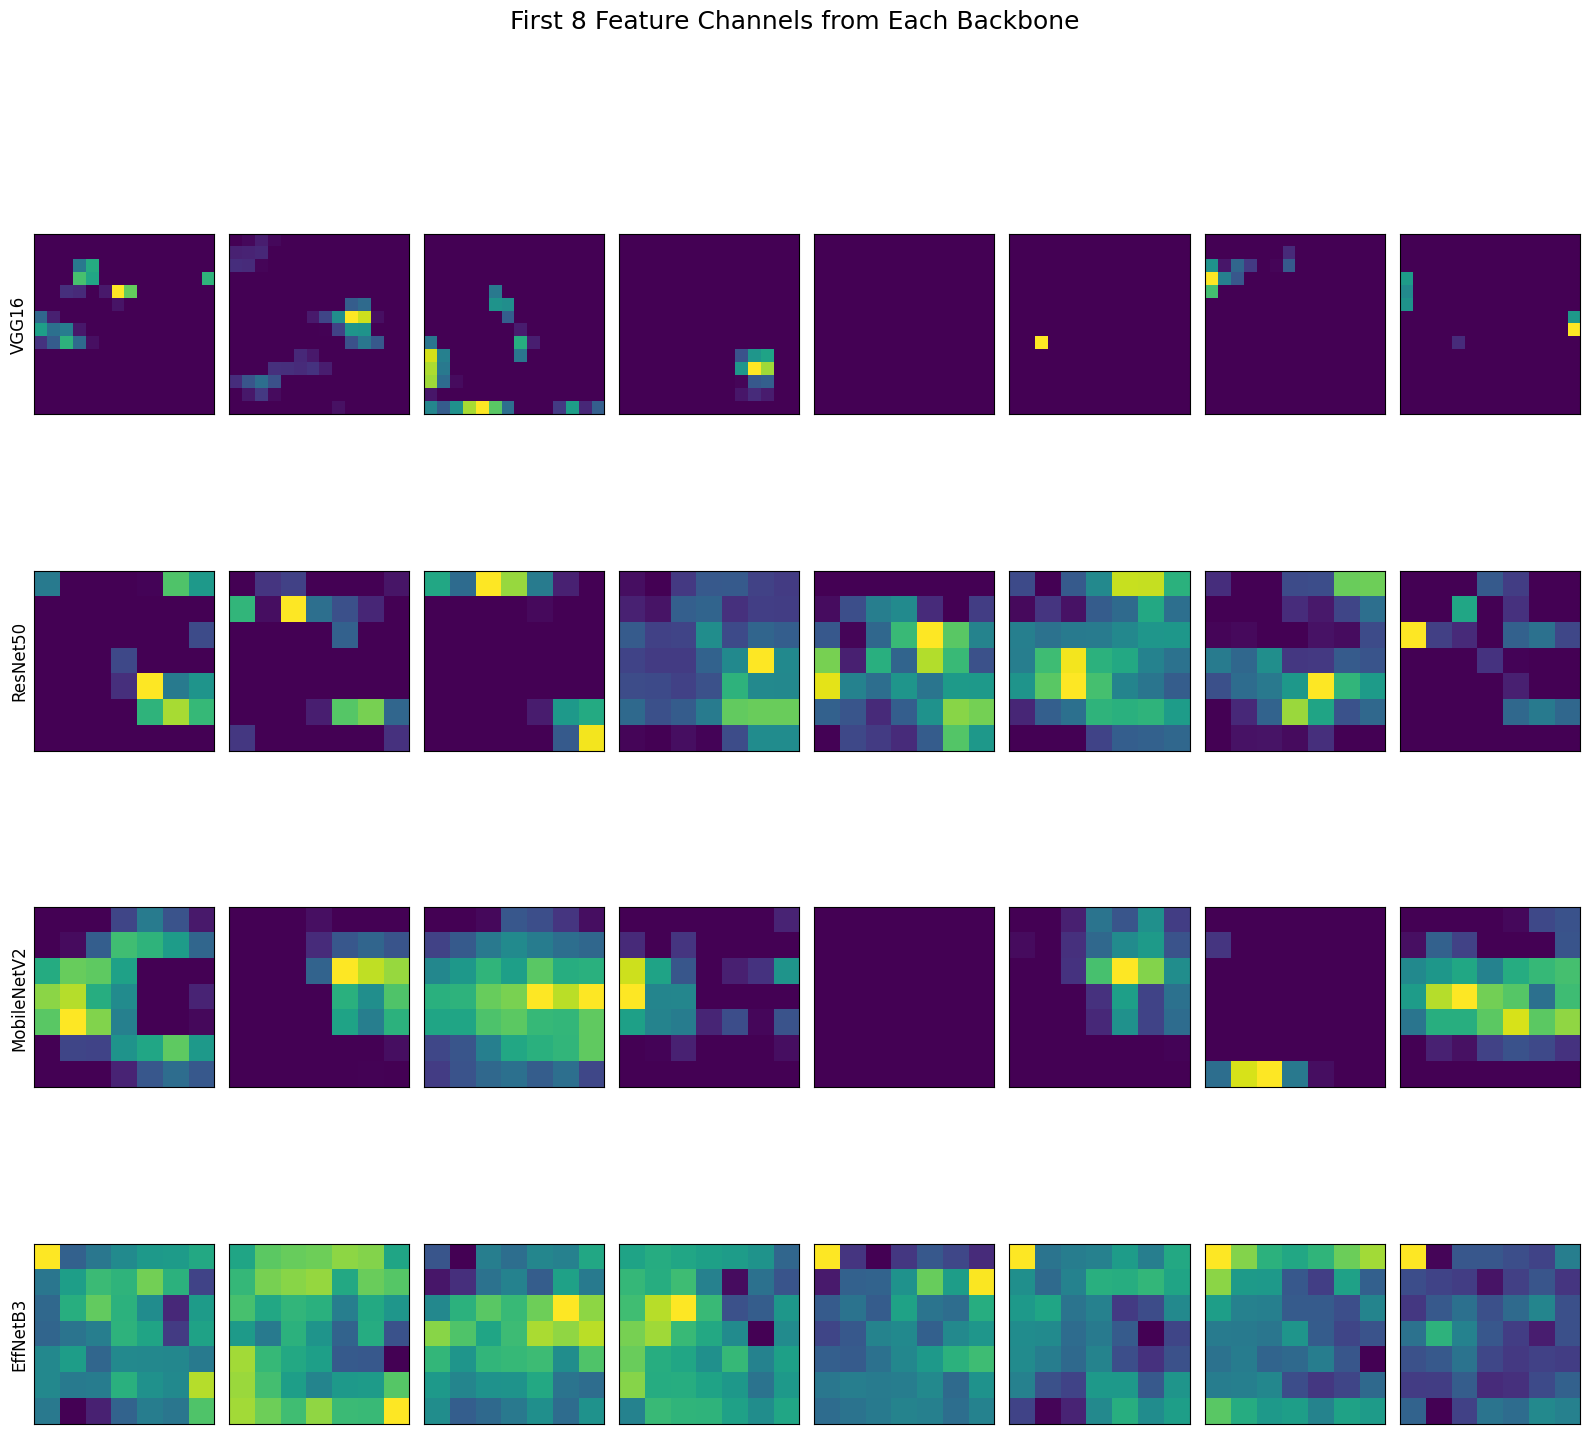

In [6]:
# Prepare your image
img = Image.open("/content/cat.jpg").convert("RGB")
tf = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[.485,.456,.406], std=[.229,.224,.225]),
])

x = tf(img).unsqueeze(0)

# Extract and plot
plt.figure(figsize=(16, 4 * len(backbones)))
for i, (name, model) in enumerate(backbones.items()):
    model.eval()
    fmap = get_feature_map(model, x, hook_layers[name])[0]
    for ch in range(8):
        plt.subplot(len(backbones), 8, i*8 + ch + 1)
        plt.imshow(fmap[ch].cpu(), cmap='viridis')
        if ch == 0:
            plt.ylabel(name, fontsize=12)
        plt.xticks([]); plt.yticks([])
plt.suptitle("First 8 Feature Channels from Each Backbone", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### DOG image input

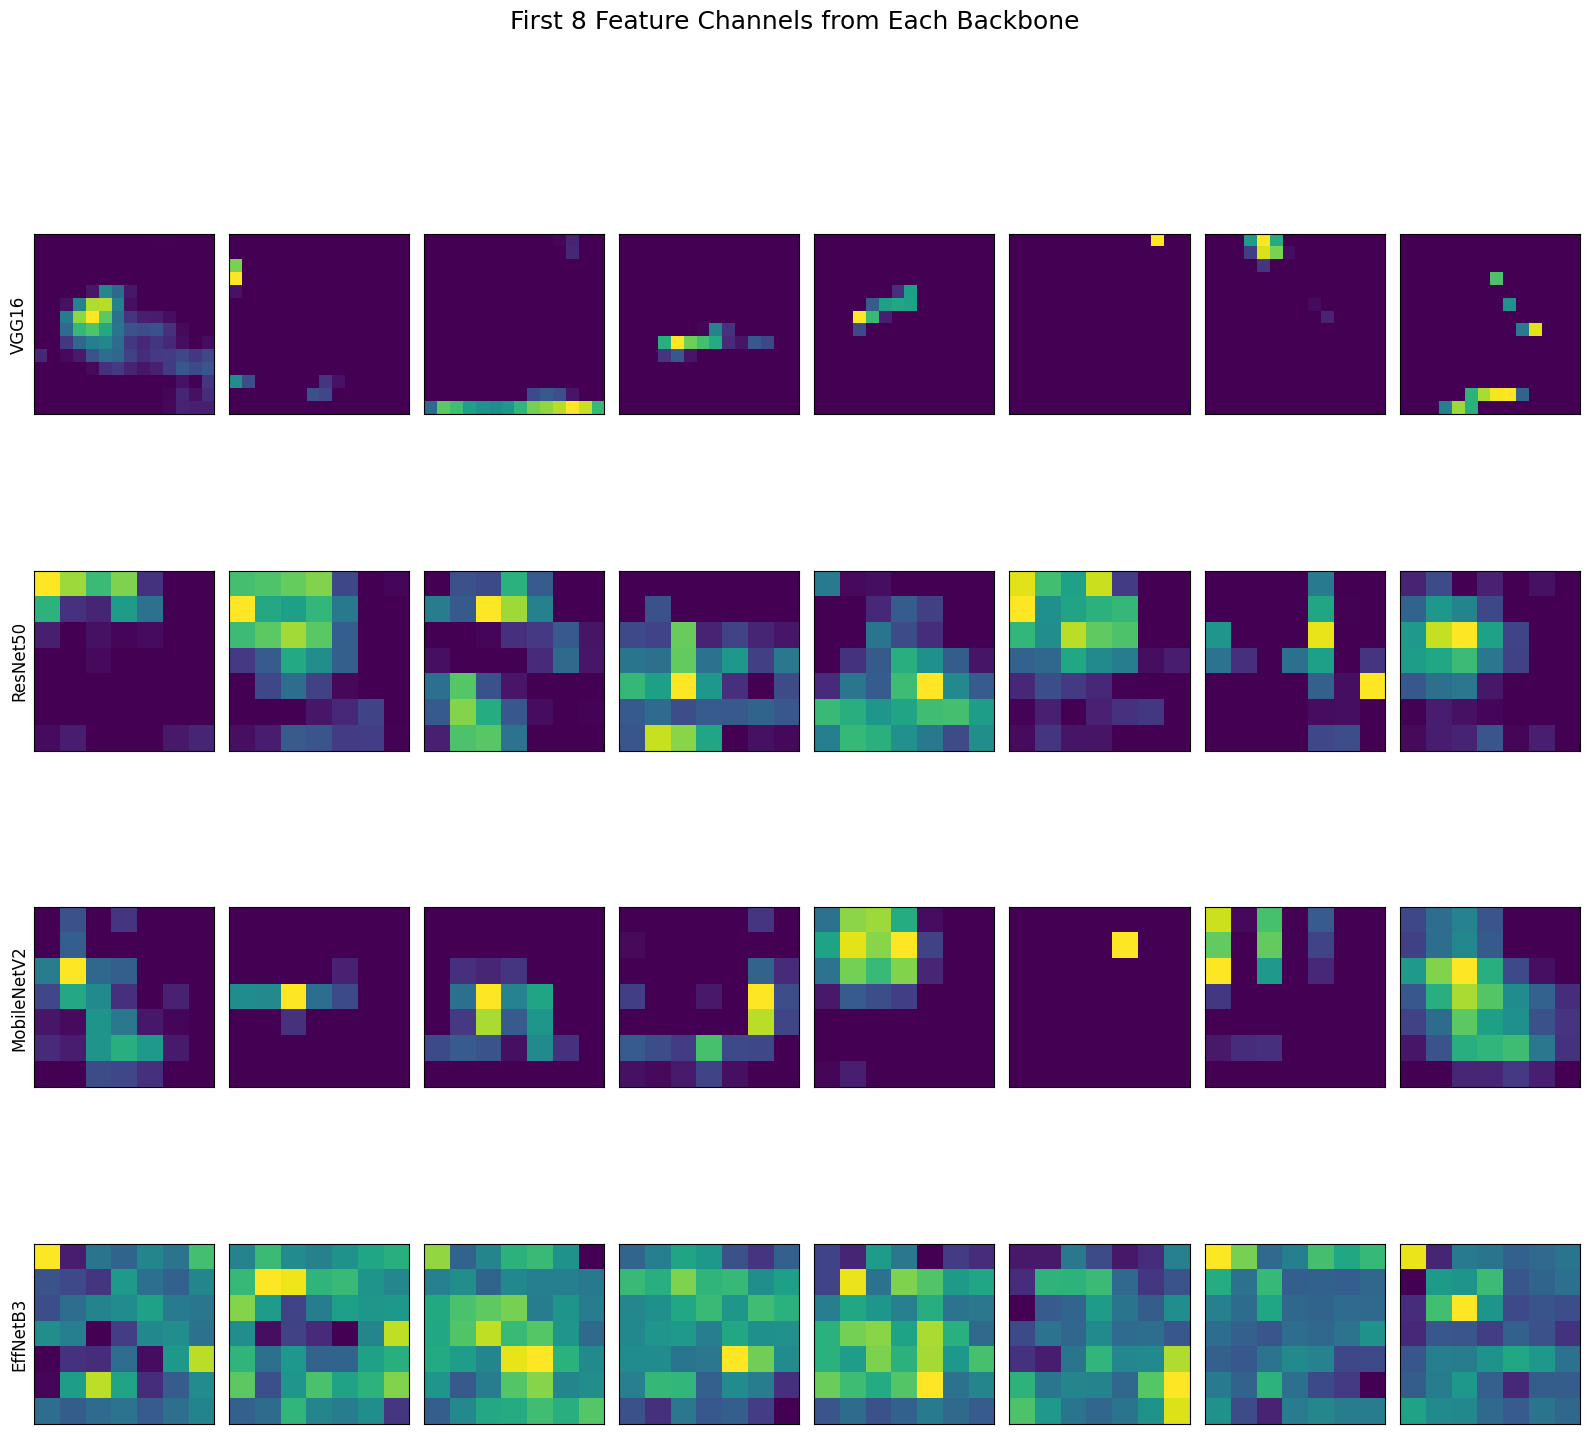

In [7]:

# Prepare your image
img = Image.open("/content/dog.jpg").convert("RGB")
tf = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[.485,.456,.406], std=[.229,.224,.225]),
])
x = tf(img).unsqueeze(0)


# Extract and plot
plt.figure(figsize=(16, 4 * len(backbones)))
for i, (name, model) in enumerate(backbones.items()):
    model.eval()
    fmap = get_feature_map(model, x, hook_layers[name])[0]
    for ch in range(8):
        plt.subplot(len(backbones), 8, i*8 + ch + 1)
        plt.imshow(fmap[ch].cpu(), cmap='viridis')
        if ch == 0:
            plt.ylabel(name, fontsize=12)
        plt.xticks([]); plt.yticks([])
plt.suptitle("First 8 Feature Channels from Each Backbone", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Understanding Backbone Features with Code

### Are Features from Pretrained Weights?
Yes. When we load backbones using `pretrained=True`, we get weights trained on **ImageNet** (1.2M images, 1000 classes). This means:
- Early layers detect **edges, blobs, colors** (generic patterns)
- Middle layers capture **shapes, textures, parts**
- Deep layers encode **semantic information** (object-level)

This transfer learning approach allows us to reuse these learned features in new tasks (classification, detection, segmentation, etc).

---

### How Many Features in Each Backbone Output?
This refers to the **number of channels** in the final feature map (i.e. depth of `[N, C, H, W]`).

| Backbone       | Final Feature Channels (`C`) | Feature Map Size (`H×W`) on 224×224 input |
|----------------|-------------------------------|-------------------------------------------|
| VGG-16         | 512                           | 7×7                                       |
| ResNet-50      | 2048                          | 7×7                                       |
| MobileNet V2   | 1280                          | 7×7                                       |
| EfficientNet B3| 1536                          | 7×7                                       |


In [ ]:
out = model(x)  # x: [1, 3, 224, 224]
print(out.shape)  # [1, C, H, W]



---

### How to Understand a Backbone Architecturally?
A backbone is a **hierarchy of blocks**, each extracting progressively abstract features. Here’s how to explore:

#### 1. **List all layers**


In [ ]:
for name, module in model.named_modules():
    print(name)


#### 2. **Access intermediate outputs**
Use hooks on `layer1`, `layer2`, ..., or block layers (e.g., `1.0.block.2.activation` in EfficientNet) to extract multi-scale features.



#### 3. **Visualize channels**
These are per-feature activations:

In [ ]:
plt.imshow(feature_map[0, ch], cmap='viridis')



### Key Concepts:
- **Feature map shape**: `[N, C, H, W]` → N=batch size, C=features, H/W=spatial dims
- **Depth (C)** increases with layers → more complex features
- **Spatial size (H×W)** decreases → summarizing bigger regions


# What Does "Detach and Attach a Head" Mean?

* **Detach head**: Remove or ignore the final layers of a model (e.g., classifier or detector) so you can reuse the **backbone** (feature extractor).
* **Attach new head**: Add a custom task-specific layer (e.g., `Linear`, `Conv2d`, segmentation upsampling head) on top of the backbone features.

---

## What You Need to Know

### 1. **Backbone Output Shape**

You must understand what the backbone returns:

```python
feats = backbone(x)
print(feats.shape)  # [B, C, H, W]
```

This shape determines what kind of new head you can attach.

### 2. **What the Original Head Does**

Most torchvision models have the classification head at the end like:

```python
resnet.fc = nn.Linear(2048, 1000)
```

For MobileNet:

```python
mobilenet.classifier = nn.Sequential(...)
```

### 3. **What You Want Your Head to Do**

* Classification → `nn.Linear(C, num_classes)`
* Detection → `nn.Conv2d(C, anchors × (classes + 4), 3, padding=1)`
* Segmentation → `nn.ConvTranspose2d`, `Upsample`, etc.

---

## How to Detach a Head

### Option 1: Use only `features`

```python
from torchvision.models import mobilenet_v2
model = mobilenet_v2(pretrained=True)
backbone = model.features  # excludes classifier
```

### Option 2: Slice off the FC from a model like ResNet

```python
from torchvision.models import resnet50
resnet = resnet50(pretrained=True)
backbone = nn.Sequential(*list(resnet.children())[:-2])  # removes avgpool & fc
```

---

## How to Attach a New Head

Let’s say the feature map from the backbone is `[B, 512, 7, 7]`:

### 1. Classification Head

```python
class ClassifierHead(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(in_channels, num_classes)

    def forward(self, x):
        x = self.pool(x).flatten(1)  # [B, C]
        return self.fc(x)
```

### 2. Detection Head

Use the version previously implemented:

* Input: `[B, C, H, W]`
* Output: `[B, H*W*A, cls]` and `[B, H*W*A, 4]`

### 3. Segmentation Head

```python
class SegHead(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, num_classes, kernel_size=16, stride=8, padding=4)

    def forward(self, x):
        return self.up(x)  # [B, num_classes, H', W']
```

---

## Full Example: Detach + Attach in PyTorch

```python
class FullModel(nn.Module):
    def __init__(self, backbone, head):
        super().__init__()
        self.backbone = backbone
        self.head = head

    def forward(self, x):
        feats = self.backbone(x)
        return self.head(feats)

# Example usage:
backbone = nn.Sequential(*list(models.resnet18(pretrained=True).children())[:-2])
head = DetectionHead(in_channels=512, num_classes=5)
model = FullModel(backbone, head)
```

---

## Summary Cheat Sheet

| Concept                       | What You Do                                                     |
| ----------------------------- | --------------------------------------------------------------- |
| **Detach head**               | Slice model up to last conv block / use `.features`             |
| **Understand feature shape**  | Run dummy input: `model(torch.randn(1, 3, 224, 224))`           |
| **Attach new head**           | Define a new `nn.Module` that consumes the feature shape        |
| **Connect backbone + head**   | Wrap into a new `FullModel(backbone, head)`                     |
| **Feature freeze (optional)** | `for param in backbone.parameters(): param.requires_grad=False` |
